# Avance 3. Baseline

**Equipo 57 — Proyecto Integrador (Gpo 10)**
Alejandro Agustín Ahedo González (A01797242) · Andrés Roberto Osuna González (A01796264) · Sandra Luz Cervantes Espinoza (A01796937)

Profesores: Dra. Liliana Ibeth Barbosa Santillán, Dra. Grettel Barceló Alonso y Dr. Luis Eduardo Falcón Morales
Socio formador: CLEAR (Coalition for Language Equity in AI Research)

---

## Objetivo

El problema de negocio de CLEAR es medir si los sistemas de reconocimiento de voz (ASR) funcionan igual de bien en todos los idiomas o si discriminan a los idiomas con menos recursos. La variable objetivo es el **error de transcripción (CER)** de cada audio.

Este avance construye dos líneas base complementarias, en la fase de **Modelado** de CRISP-ML(Q):

1. **Línea base de reconocimiento de voz: Omnilingual ASR CTC 300M.** Transcribe los audios de FLEURS en los 102 idiomas y fija el desempeño mínimo contra el que se compararán los modelos más avanzados (Whisper, SeamlessM4T, Qwen3-ASR y los modelos por API).
2. **Línea base predictiva.** Un modelo que intenta predecir el CER de Omnilingual a partir de las características seleccionadas en el Avance 2. Responde si el error es predecible con información del idioma y del audio, o si se comporta como azar.

| Criterio de la rúbrica | Sección |
|---|---|
| Algoritmo | 2 |
| Métrica | 4 |
| Desempeño mínimo | 5 |
| Sub/sobreajuste | 6.2 y 7 |
| Características importantes | 8 |
| Respuestas a las preguntas del avance | 9 |

**Requisitos para ejecutarlo:** entorno con **GPU** (una T4 basta; en CPU funciona, pero tarda más) y, en Google Drive, la caché de audio `fleurs_cache_seed42_n50` y el archivo `fleurs_results/avance2_features.csv` que generó el Avance 2. Se ejecuta de principio a fin con *Entorno de ejecución → Ejecutar todas*.

## 1. Configuración

In [1]:
!pip install -q jiwer transformers accelerate sentencepiece
print("done")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 42.1 MB/s eta 0:00:00
done


In [2]:
import os, re, time, pickle, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import jiwer
import torch
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "no GPU (inference will be slower)")

Device: cuda | Tesla T4


In [3]:
from google.colab import drive
drive.mount("/content/drive")

DRIVE = "/content/drive/MyDrive"
CACHE_DIR = f"{DRIVE}/fleurs_cache_seed42_n50"
FEATURES_PATH = f"{DRIVE}/fleurs_results/avance2_features.csv"
OUTPUT_DIR = f"{DRIVE}/fleurs_results"
PREVIOUS_RESULTS = [f"{DRIVE}/fleurs_results2/fleurs_asr_results.csv", f"{DRIVE}/fleurs_results/fleurs_asr_results.csv"]

assert os.path.isdir(CACHE_DIR), f"Audio cache not found: {CACHE_DIR}"
assert os.path.exists(FEATURES_PATH), f"Avance 2 features not found: {FEATURES_PATH}"
os.makedirs(OUTPUT_DIR, exist_ok=True)

LANG_CODES = sorted(f[:-4] for f in os.listdir(CACHE_DIR) if f.endswith(".pkl"))
print(f"{len(LANG_CODES)} languages in the audio cache")

Mounted at /content/drive
102 languages in the audio cache


## 2. Selección del algoritmo

### 2.1 Línea base de reconocimiento de voz: Omnilingual ASR CTC 300M

**Tipo de datos.** Los datos de entrada son **no estructurados**: audio de voz (señales de 16 kHz) y su transcripción en texto. Transformar audio en texto requiere un modelo acústico entrenado con miles de horas de voz; no se puede resolver con un algoritmo tabular.

**Cantidad de datos.** Tenemos 50 audios por idioma (5,087 en total, unos 12 segundos cada uno). Es suficiente para **evaluar**, pero muy poco para **entrenar** un reconocedor de voz, que necesita cientos de horas por idioma. Por eso la línea base es un modelo **preentrenado**, aplicado sin ajuste (*zero-shot*).

**Por qué Omnilingual y no los otros modelos del estudio:**

| Modelo | Parámetros | Idiomas de FLEURS que cubre | Arquitectura | Riesgo de alucinación |
|---|---|---|---|---|
| **Omnilingual ASR CTC** | **300M** | **102 de 102** | **CTC (sin modelo de lenguaje)** | **No** |
| Whisper-Large-v3 | 1,550M | 83 | Codificador-decodificador | Sí (ciclos de repetición) |
| SeamlessM4T v2 | 2,300M | 90 | Codificador-decodificador | Sí |
| Qwen3-ASR | 600M | 30 | Modelo de lenguaje con audio | Sí |

1. **Cobertura total.** Una línea base para un estudio de equidad debe existir en todos los idiomas; si no, los idiomas con menos recursos se quedarían sin referencia.
2. **Simplicidad.** Es el modelo más pequeño y su arquitectura es la más simple: CTC (*Connectionist Temporal Classification*, Graves et al., 2006) asigna un carácter a cada fragmento de 20 ms de audio, sin un modelo de lenguaje que reescriba el texto. Es el equivalente, en voz, de un modelo lineal frente a uno profundo: cualquier modelo más complejo debería superarlo.
3. **Interpretabilidad y estabilidad.** Como cada carácter corresponde a un fragmento de audio, sus errores son locales (un sonido mal reconocido) y no puede generar texto que no está en el audio. En el Avance 2, Whisper produjo 70 transcripciones alucinadas y Omnilingual ninguna. Su error refleja reconocimiento, no fallas de generación.
4. **Costo.** En la evaluación del equipo fue unas 16 veces más rápido que Whisper por audio (0.02 s contra 0.36 s en GPU).

### 2.2 Línea base predictiva: ¿se puede anticipar el error?

**Tipo de datos.** Las características del Avance 2 son **estructuradas** (tabulares): métricas del audio y del texto por cada grabación, y atributos del idioma (familia de escritura, región, número de hablantes, si usa espacios).

**Cantidad de datos.** 5,087 filas, pero solo **102 idiomas**. Muchas características son constantes dentro de un idioma, así que en la práctica el modelo aprende de 102 grupos. Con tan pocos grupos, un modelo complejo (red neuronal, *boosting* profundo) memorizaría los idiomas en vez de generalizar.

**Interpretabilidad.** Para CLEAR es más valioso entender **por qué** falla un idioma que predecir su error con precisión. Por eso se eligen modelos cuyas decisiones se pueden explicar:

- **Modelo nulo (*DummyRegressor*):** siempre predice el CER promedio. Representa el azar: si un modelo no lo supera, las características no contienen información útil.
- **Regresión Ridge:** modelo lineal con regularización L2 (Géron, 2022, cap. 4). Sus coeficientes, sobre características estandarizadas, dicen directamente cuánto sube o baja el error con cada característica. La regularización controla el efecto de las variables correlacionadas, como `ref_chars` y `ref_words`.
- **Random Forest:** conjunto de árboles de decisión (Géron, 2022, cap. 7). Capta relaciones no lineales e interacciones (por ejemplo, escritura × región) sin necesidad de escalar las variables, y da una medida de importancia de cada característica. Se limita su profundidad (`max_depth=8`, `min_samples_leaf=20`) para que no memorice.

**Validación por idioma.** Se usa *GroupKFold* con 5 particiones **por idioma**: ningún idioma aparece a la vez en entrenamiento y prueba. Una validación aleatoria por grabación pondría audios del mismo idioma en ambos lados y el modelo "adivinaría" el idioma, con un desempeño engañosamente alto. Aquí se evalúa el caso real: predecir el error en un idioma que el modelo nunca vio.

## 3. Inferencia de Omnilingual

Se carga el modelo desde Hugging Face (`aadel4/omniASR-CTC-300M`, la versión compatible con `transformers` que usamos en la evaluación del equipo). Para cada audio:

1. Se convierte a un solo canal y a 16 kHz, el formato con que se entrenó el modelo.
2. El modelo produce una distribución de probabilidad sobre caracteres para cada fragmento de 20 ms.
3. Se elige el carácter más probable en cada fragmento (decodificación *greedy*) y se eliminan las repeticiones y los símbolos vacíos de CTC.

El proceso es por lotes. Si la GPU se queda sin memoria, el lote se reduce a la mitad y se reintenta. Dentro de un lote, los audios cortos se rellenan con silencio hasta igualar al más largo; ese relleno cambia ligeramente algunas transcripciones, así que el resultado depende un poco del tamaño de lote (ver la verificación al final de esta sección).

**Transcripciones guardadas.** La inferencia tarda unos 30 minutos en una T4. La primera ejecución guarda las transcripciones en Drive (`fleurs_results/avance3_omnilingual_predictions.csv`); si el archivo ya existe y `USE_SAVED_PREDICTIONS = True`, se cargan de ahí en lugar de volver a transcribir. Así, todas las cifras de este notebook corresponden exactamente a la misma ejecución del modelo. Para transcribir de nuevo, basta con cambiar la variable a `False`.

In [4]:
from transformers import AutoProcessor, AutoModelForCTC

OMNI_MODEL = "aadel4/omniASR-CTC-300M"
omni_processor = AutoProcessor.from_pretrained(OMNI_MODEL)
omni_model = AutoModelForCTC.from_pretrained(OMNI_MODEL).to(device).eval()
print(f"Omnilingual ASR loaded: {sum(p.numel() for p in omni_model.parameters()) / 1e6:.0f}M parameters on {device}")

def transcribe_batch(arrays):
    inputs = omni_processor(arrays, sampling_rate=16000, return_tensors="pt", padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        logits = omni_model(**inputs).logits
    ids = torch.argmax(logits, dim=-1)
    return [t.strip() for t in omni_processor.batch_decode(ids)]

preprocessor_config.json:   0%|          | 0.00/187 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/233 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.97k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/145k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.30GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/424 [00:00<?, ?it/s]

Omnilingual ASR loaded: 325M parameters on cuda


In [5]:
def prepare_audio(audio):
    x = np.asarray(audio["array"], dtype=np.float32)
    if x.ndim > 1:
        x = x.mean(axis=0)
    sr = audio["sampling_rate"]
    if sr != 16000:
        import torchaudio
        x = torchaudio.functional.resample(torch.tensor(x), sr, 16000).numpy()
    return x

def predict_in_batches(items, batch_size):
    """Runs transcribe_batch over items. On CUDA out-of-memory, halves the batch and retries."""
    preds, i, bs = [], 0, batch_size
    while i < len(items):
        chunk = items[i:i + bs]
        try:
            preds.extend(transcribe_batch(chunk))
            i += len(chunk)
        except torch.cuda.OutOfMemoryError:
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            if bs == 1:
                raise
            bs = max(1, bs // 2)
            print(f"   out of memory, batch size reduced to {bs}")
    return preds, bs

USE_SAVED_PREDICTIONS = True
PREDICTIONS_PATH = f"{OUTPUT_DIR}/avance3_omnilingual_predictions.csv"

def run_inference():
    BATCH_SIZE = 32 if device == "cuda" else 8
    rows, bs = [], BATCH_SIZE
    t_start = time.time()
    for n, lang in enumerate(LANG_CODES, 1):
        with open(os.path.join(CACHE_DIR, f"{lang}.pkl"), "rb") as f:
            samples = pickle.load(f)
        clips = [prepare_audio(s["audio"]) for s in samples]
        t0 = time.time()
        preds, bs = predict_in_batches(clips, bs)
        per_clip = (time.time() - t0) / len(clips)
        for pos, (s, clip, pred) in enumerate(zip(samples, clips, preds)):
            rows.append({"language_code": lang, "language": s.get("language", lang), "clip_pos": pos,
                         "sample_id": s["id"], "reference": s["transcription"], "prediction": pred,
                         "audio_seconds": len(clip) / 16000, "inference_seconds": per_clip})
        del samples, clips
        if n % 20 == 0 or n == len(LANG_CODES):
            print(f"{n}/{len(LANG_CODES)} languages | {(time.time() - t_start) / 60:.1f} min")
    result = pd.DataFrame(rows)
    result.to_csv(PREDICTIONS_PATH, index=False, encoding="utf-8")
    total = time.time() - t_start
    print(f"\n{len(result)} transcriptions in {total / 60:.1f} min")
    print(f"Real-time factor: {total / result['audio_seconds'].sum():.4f} seconds of compute per second of audio")
    return result

if USE_SAVED_PREDICTIONS and os.path.exists(PREDICTIONS_PATH):
    keep = ["language_code", "language", "clip_pos", "sample_id", "reference", "prediction", "audio_seconds", "inference_seconds"]
    baseline = pd.read_csv(PREDICTIONS_PATH, keep_default_na=False, na_values=[""])[keep]
    print(f"Loaded {len(baseline)} saved transcriptions from {PREDICTIONS_PATH}")
    print(f"Mean inference time: {baseline['inference_seconds'].mean():.3f} s per recording "
          f"(real-time factor {baseline['inference_seconds'].sum() / baseline['audio_seconds'].sum():.4f})")
else:
    baseline = run_inference()

Loaded 5087 saved transcriptions from /content/drive/MyDrive/fleurs_results/avance3_omnilingual_predictions.csv
Mean inference time: 0.324 s per recording (real-time factor 0.0247)


In [6]:
# Reproducibility check against the team's earlier evaluation run (Avance 1), if available
prev_path = next((p for p in PREVIOUS_RESULTS if os.path.exists(p)), None)
if prev_path:
    prev = pd.read_csv(prev_path)
    prev = prev[(prev["model"] == "Omnilingual ASR CTC 300M") & (prev["status"] == "OK")].copy()
    prev["clip_pos"] = prev.groupby("language_code").cumcount()
    cmp = baseline.merge(prev[["language_code", "clip_pos", "prediction"]], on=["language_code", "clip_pos"],
                         suffixes=("", "_previous"))
    same = (cmp["prediction"].fillna("").str.strip() == cmp["prediction_previous"].fillna("").astype(str).str.strip()).mean()
    cer_now = np.mean([jiwer.cer(r, p) if r else 0 for r, p in zip(cmp["reference"].str.lower(), cmp["prediction"].fillna("").str.lower())])
    cer_prev = np.mean([jiwer.cer(r, p) if r else 0 for r, p in zip(cmp["reference"].str.lower(), cmp["prediction_previous"].fillna("").astype(str).str.lower())])
    print(f"Identical transcriptions to the previous run: {same:.1%} of {len(cmp)}")
    print(f"Raw CER (no normalization) this run: {cer_now:.2%} | previous run: {cer_prev:.2%} | difference: {(cer_now - cer_prev) * 100:+.2f} points")
else:
    print("No previous run found; reproducibility check skipped")

Identical transcriptions to the previous run: 73.8% of 5087
Raw CER (no normalization) this run: 13.15% | previous run: 13.18% | difference: -0.03 points


**Lectura de la verificación.** En esta ejecución, cerca de tres cuartas partes de las transcripciones son idénticas al de la evaluación del Avance 1, y el CER total cambia menos de una décima de punto. Las diferencias vienen del relleno de los lotes: la evaluación anterior corrió en una GPU con más memoria y lotes de 32 audios, y aquí la T4 tuvo que bajar a lotes de 8 y 4, así que cada audio se procesó con un relleno distinto. Afecta letras sueltas, no el desempeño, y por eso las transcripciones se guardan y se reutilizan.

## 4. Métrica

### 4.1 Métrica de la línea base de voz: CER

- **CER (*Character Error Rate*)**: proporción de caracteres que hay que sustituir, borrar o insertar para convertir la transcripción del modelo en la referencia. 0% es perfecto. Es la **métrica principal**.
- **WER (*Word Error Rate*)**: lo mismo, contando palabras. Solo se reporta como métrica secundaria en los idiomas que separan palabras con espacios.

**Por qué CER y no WER, dado el problema de negocio.** CLEAR quiere comparar la calidad **entre idiomas**, así que la métrica debe significar lo mismo en todos los sistemas de escritura:

1. El WER no existe en idiomas sin espacios (mandarín, cantonés, japonés, tailandés, lao, jemer y birmano): ahí una "palabra" puede ser una oración completa, y un solo carácter erróneo cuenta como 100% de error.
2. El WER castiga de más a los idiomas aglutinantes (finés, turco, suajili), donde una palabra larga contiene lo que en inglés serían cuatro, y basta un sufijo mal reconocido para perderla entera. Eso haría parecer peores a esos idiomas por su morfología, no por el modelo, y sesgaría precisamente la comparación de equidad que pide CLEAR.
3. El artículo de Omnilingual usa el CER como métrica principal y fija el umbral de calidad en CER ≤ 10 (Omnilingual ASR Team, 2025), lo que permite comparar con una referencia publicada.

**Normalización.** Se aplica la misma de los avances anteriores: Unicode NFKC, minúsculas y eliminación de puntuación y símbolos, conservando los signos vocálicos de las escrituras índicas. En los siete idiomas sin espacios se eliminan todos los espacios antes del CER, porque las referencias de FLEURS en chino insertan un espacio entre cada carácter (Avance 2).

**Corrección del serbio.** El serbio se escribe oficialmente en dos alfabetos. FLEURS tiene las referencias en latino y Omnilingual responde en cirílico, con transcripciones casi perfectas que el CER contaría como 78% de error. Como la correspondencia entre ambos alfabetos es uno a uno, se translitera la predicción a latino antes de medir. El urdu tiene un problema parecido (el modelo responde en devanagari, la escritura del hindi), pero ahí no existe una conversión directa, así que se deja sin corregir y se señala.

### 4.2 El equivalente a las clases desbalanceadas

Este problema no es de clasificación, pero tiene dos desbalances que afectan cómo se resume la métrica:

1. **Desbalance de escrituras y regiones.** La mayoría de los idiomas usa escritura latina. Un promedio sobre todas las grabaciones juntas (**micro**) pesa más a los grupos grandes. Por eso la cifra principal es el **promedio por idioma (macro)**: primero se promedia dentro de cada idioma y luego entre idiomas, de modo que cada idioma pesa lo mismo. Es el análogo de usar *balanced accuracy* en clasificación.
2. **Cola larga.** Unos pocos audios tienen errores muy altos. Se reporta también la **mediana**, que no se mueve por esos casos, y el CER se acota a 100% (`cer_capped`) en la parte predictiva.

In [7]:
def normalize_text(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    text = "".join(" " if unicodedata.category(c)[0] in "PS" else c for c in text)
    return re.sub(r"\s+", " ", text).strip()

NO_SPACE_LANGS = {"cmn_hans_cn", "yue_hant_hk", "ja_jp", "th_th", "lo_la", "km_kh", "my_mm"}

SERBIAN_CYR_TO_LAT = {
    "а": "a", "б": "b", "в": "v", "г": "g", "д": "d", "ђ": "đ", "е": "e", "ж": "ž", "з": "z", "и": "i",
    "ј": "j", "к": "k", "л": "l", "љ": "lj", "м": "m", "н": "n", "њ": "nj", "о": "o", "п": "p", "р": "r",
    "с": "s", "т": "t", "ћ": "ć", "у": "u", "ф": "f", "х": "h", "ц": "c", "ч": "č", "џ": "dž", "ш": "š",
}
def serbian_to_latin(text):
    return "".join(SERBIAN_CYR_TO_LAT.get(c, c) for c in text)

baseline["prediction"] = baseline["prediction"].fillna("").astype(str)
baseline["ref_norm"] = baseline["reference"].map(normalize_text)
baseline["pred_norm"] = baseline["prediction"].map(normalize_text)
is_sr = baseline["language_code"] == "sr_rs"
baseline.loc[is_sr, "pred_norm"] = baseline.loc[is_sr, "pred_norm"].map(serbian_to_latin)
no_space = baseline["language_code"].isin(NO_SPACE_LANGS)
for col in ["ref_norm", "pred_norm"]:
    baseline.loc[no_space, col] = baseline.loc[no_space, col].str.replace(" ", "", regex=False)
baseline = baseline[baseline["ref_norm"].str.len() > 0].copy()

baseline["cer"] = [jiwer.cer(r, p) for r, p in zip(baseline["ref_norm"], baseline["pred_norm"])]
baseline["wer"] = [np.nan if l in NO_SPACE_LANGS else jiwer.wer(r, p)
                   for l, r, p in zip(baseline["language_code"], baseline["ref_norm"], baseline["pred_norm"])]
baseline["cer_capped"] = baseline["cer"].clip(upper=1.0)

example = baseline[baseline["language_code"] == "sr_rs"].iloc[0]
print("Serbian example after transliteration:")
print("  original  :", example["prediction"])
print("  reference :", example["ref_norm"])
print("  prediction:", example["pred_norm"])
print(f"  CER: {example['cer']:.1%}")

Serbian example after transliteration:
  original  : сегрегација и рекомбиновање утичу на стално мешање варијаци између два фонда у свакој генерацији
  reference : segregacija i rekombinovanje utiču na stalno mešanje varijacija između dva fonda u svakoj generaciji
  prediction: segregacija i rekombinovanje utiču na stalno mešanje varijaci između dva fonda u svakoj generaciji
  CER: 2.0%


Omnilingual baseline on 102 languages, 5087 transcriptions
WER computed on 95 languages that separate words with spaces


,CER,WER
macro mean (per language),11.44,36.88
macro median (per language),9.11,33.60
micro (whole corpus),10.72,36.11


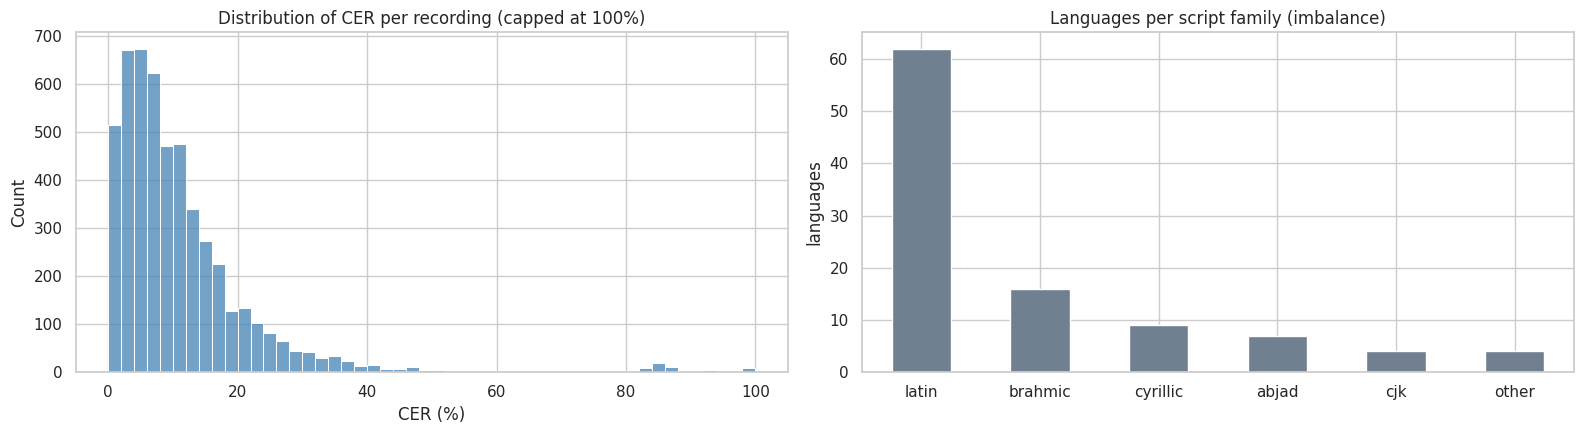

In [8]:
spaced = baseline[~baseline["language_code"].isin(NO_SPACE_LANGS)]
per_lang = baseline.groupby(["language_code", "language"]).agg(
    cer=("cer", "mean"), wer=("wer", "mean"), clips=("cer", "size")).reset_index()

summary = pd.DataFrame({
    "CER": [per_lang["cer"].mean(), per_lang["cer"].median(),
            jiwer.cer(baseline["ref_norm"].tolist(), baseline["pred_norm"].tolist())],
    "WER": [per_lang["wer"].mean(), per_lang["wer"].median(),
            jiwer.wer(spaced["ref_norm"].tolist(), spaced["pred_norm"].tolist())],
}, index=["macro mean (per language)", "macro median (per language)", "micro (whole corpus)"]).mul(100).round(2)
print(f"Omnilingual baseline on {per_lang.shape[0]} languages, {len(baseline)} transcriptions")
print(f"WER computed on {spaced['language_code'].nunique()} languages that separate words with spaces")
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
sns.histplot(baseline["cer_capped"] * 100, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of CER per recording (capped at 100%)")
axes[0].set_xlabel("CER (%)")
families = pd.read_csv(FEATURES_PATH, usecols=lambda c: c.startswith("script_family_") or c in ["language_code", "model"])
families = families[families["model"] == "Omnilingual ASR CTC 300M"].drop_duplicates("language_code")
fam_counts = families.drop(columns=["language_code", "model"]).sum().sort_values(ascending=False)
fam_counts.index = fam_counts.index.str.replace("script_family_", "", regex=False)
fam_counts.plot(kind="bar", ax=axes[1], color="slategray")
axes[1].set_title("Languages per script family (imbalance)")
axes[1].set_ylabel("languages")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

**Lectura.** El histograma muestra la cola larga: la mayoría de las grabaciones tiene un CER bajo y unas pocas tienen errores muy altos, por eso la mediana queda por debajo de la media. La gráfica de barras muestra el desbalance de escrituras: el grupo latino es varias veces más grande que cualquier otro, lo que justifica resumir por idioma (macro) en lugar de por grabación (micro).

## 5. Desempeño mínimo y verificación

### 5.1 Referencias históricas

Sí existe un desempeño histórico con el que comparar:

1. **Publicado:** el artículo de Omnilingual reporta, para este mismo modelo (300M CTC), un **CER promedio de 11.7% (dev) y 11.8% (test)** en 81 idiomas de FLEURS (Omnilingual ASR Team, 2025, tabla 5).
2. **Umbral de calidad publicado:** el mismo artículo considera que un idioma tiene calidad aceptable si su **CER ≤ 10%**, es decir, en promedio no más de un error cada diez caracteres. Con este umbral, su modelo más grande (7B) alcanza la calidad en el 78% de 1,570 idiomas.
3. **Interno:** la evaluación del equipo en el Avance 1, que la celda de reproducibilidad de la sección 3 compara transcripción por transcripción.

### 5.2 Criterios de aceptación

- **Línea base de voz.** Se acepta si su CER promedio por idioma es comparable con el publicado (alrededor de 12%). Un idioma alcanza **calidad aceptable** si su CER ≤ 10%. La **cobertura** (porcentaje de idiomas que lo alcanzan) es la cifra que los modelos de los siguientes avances deben mejorar.
- **Equidad (marco de CLEAR).** Se aplican las métricas del Experimento 1 al CER por idioma: el **coeficiente de Gini** (0 = mismo error en todos los idiomas; cercano a 1 = error concentrado en pocos) y la **razón máximo/mínimo** (cuántas veces peor es el peor idioma que el mejor). Como advirtió CLEAR en el Experimento 2, un Gini bajo puede significar que el modelo es igual de malo en todas partes, así que se interpreta siempre junto con la cobertura.
- **Línea base predictiva.** No hay un histórico. El desempeño mínimo es el del **modelo nulo** (predecir siempre el promedio), que representa el azar. El modelo predictivo se acepta si reduce el error del modelo nulo en idiomas que no vio y si esa mejora es estadísticamente distinta del azar (prueba de permutación, sección 6.3).

In [9]:
def gini(x):
    """Gini coefficient with the sorting shortcut (same function as the Experiment 1 repository)."""
    x = np.sort(np.asarray(x, dtype=np.float64).flatten())
    n = len(x)
    if n == 0 or x.sum() == 0:
        return np.nan
    ranks = np.arange(1, n + 1)
    return (2 * np.sum(ranks * x)) / (n * np.sum(x)) - (n + 1) / n

PUBLISHED_CER = 11.8
QUALITY_CER = 0.10
lang_cer = per_lang.set_index("language")["cer"]
SCRIPT_MISMATCH = {"Urdu"}

checks = pd.DataFrame([
    ["Macro mean CER (%)", round(lang_cer.mean() * 100, 2), f"~{PUBLISHED_CER} (paper, FLEURS-81 test)"],
    ["Macro mean CER without Urdu (%)", round(lang_cer.drop(list(SCRIPT_MISMATCH), errors="ignore").mean() * 100, 2), "output script mismatch removed"],
    ["Macro median CER (%)", round(lang_cer.median() * 100, 2), ""],
    ["Coverage: languages with CER <= 10% (%)", round((lang_cer <= QUALITY_CER).mean() * 100, 1), "quality threshold from the paper"],
    ["Gini of CER across languages", round(gini(lang_cer), 3), "0 = equal error in every language"],
    ["Max / min CER ratio", round(lang_cer.max() / lang_cer.min(), 1), f"{lang_cer.idxmax()} vs {lang_cer.idxmin()}"],
], columns=["measure", "Omnilingual baseline", "reference"]).set_index("measure")
display(checks)

gap = lang_cer.mean() * 100 - PUBLISHED_CER
verdict = "consistent with" if abs(gap) <= 2 else ("worse than" if gap > 0 else "better than")
print(f"The baseline macro CER is {verdict} the published value ({gap:+.1f} points).")

,Omnilingual baseline,reference
measure,,
Macro mean CER (%),11.440,"~11.8 (paper, FLEURS-81 test)"
Macro mean CER without Urdu (%),10.860,output script mismatch removed
Macro median CER (%),9.110,
Coverage: languages with CER <= 10% (%),52.900,quality threshold from the paper
Gini of CER across languages,0.299,0 = equal error in every language
Max / min CER ratio,19.600,Urdu vs Spanish


The baseline macro CER is consistent with the published value (-0.4 points).


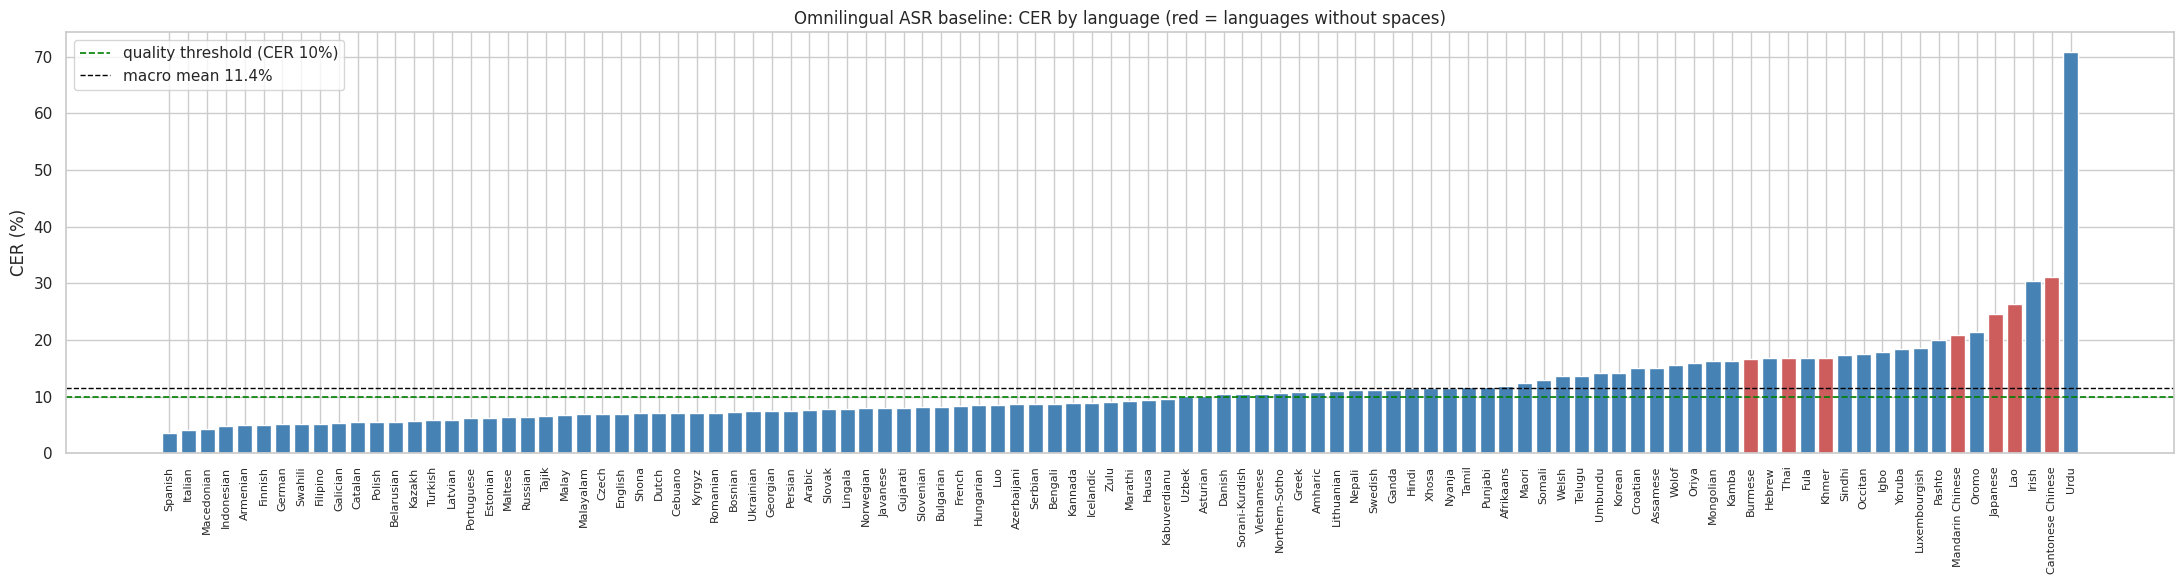

Best 10 languages:


,language,cer,wer
20,Spanish,3.6,11.7
39,Italian,4.1,13.4
58,Macedonian,4.2,18.7
36,Indonesian,4.7,23.1
35,Armenian,4.9,25.9
24,Finnish,5.0,26.4
17,German,5.1,19.1
86,Swahili,5.2,21.6
25,Filipino,5.2,16.7
28,Galician,5.4,21.4


Worst 10 languages:


,language,cer,wer
99,Yoruba,18.5,56.4
50,Luxembourgish,18.6,60.4
75,Pashto,19.9,49.6
13,Mandarin Chinese,20.9,NaN
71,Oromo,21.4,80.1
40,Japanese,24.5,NaN
53,Lao,26.3,NaN
27,Irish,30.4,69.6
100,Cantonese Chinese,31.1,NaN
94,Urdu,70.8,89.0


In [10]:
per_lang_sorted = per_lang.sort_values("cer")
fig, ax = plt.subplots(figsize=(22, 6))
colors = ["indianred" if c in NO_SPACE_LANGS else "steelblue" for c in per_lang_sorted["language_code"]]
ax.bar(per_lang_sorted["language"], per_lang_sorted["cer"] * 100, color=colors)
ax.axhline(QUALITY_CER * 100, ls="--", c="green", lw=1.2, label="quality threshold (CER 10%)")
ax.axhline(per_lang["cer"].mean() * 100, ls="--", c="black", lw=1, label=f"macro mean {per_lang['cer'].mean():.1%}")
ax.set_ylabel("CER (%)")
ax.set_title("Omnilingual ASR baseline: CER by language (red = languages without spaces)")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend()
plt.tight_layout()
plt.show()

fmt = lambda d: d.assign(cer=(d.cer * 100).round(1), wer=(d.wer * 100).round(1))[["language", "cer", "wer"]]
print("Best 10 languages:"); display(fmt(per_lang_sorted.head(10)))
print("Worst 10 languages:"); display(fmt(per_lang_sorted.tail(10)))

### 5.3 Desempeño por grupo

Se unen las transcripciones con las características del Avance 2 por idioma y posición del audio, y se desagrega el CER por familia de escritura y región. Esto muestra si la línea base trata peor a algún grupo de idiomas.

Joined 5087 of 5087 transcriptions with the Avance 2 features
CER (%) and coverage (% of languages with CER <= 10%) by script family:


,languages,cer,coverage
script_family,,,
cyrillic,9,7.4,89.0
other,4,8.5,50.0
latin,62,9.9,60.0
brahmic,16,13.1,31.0
abjad,7,21.5,29.0
cjk,4,22.7,0.0


By region:


,languages,cer,coverage
region,,,
eastern_europe,16,7.0,94.0
western_europe,25,9.7,64.0
central_asia_middle_east_north_africa,12,10.2,58.0
south_east_asia,11,11.9,45.0
sub_saharan_africa,20,12.4,30.0
south_asia,14,15.8,36.0
cjk,4,22.7,0.0


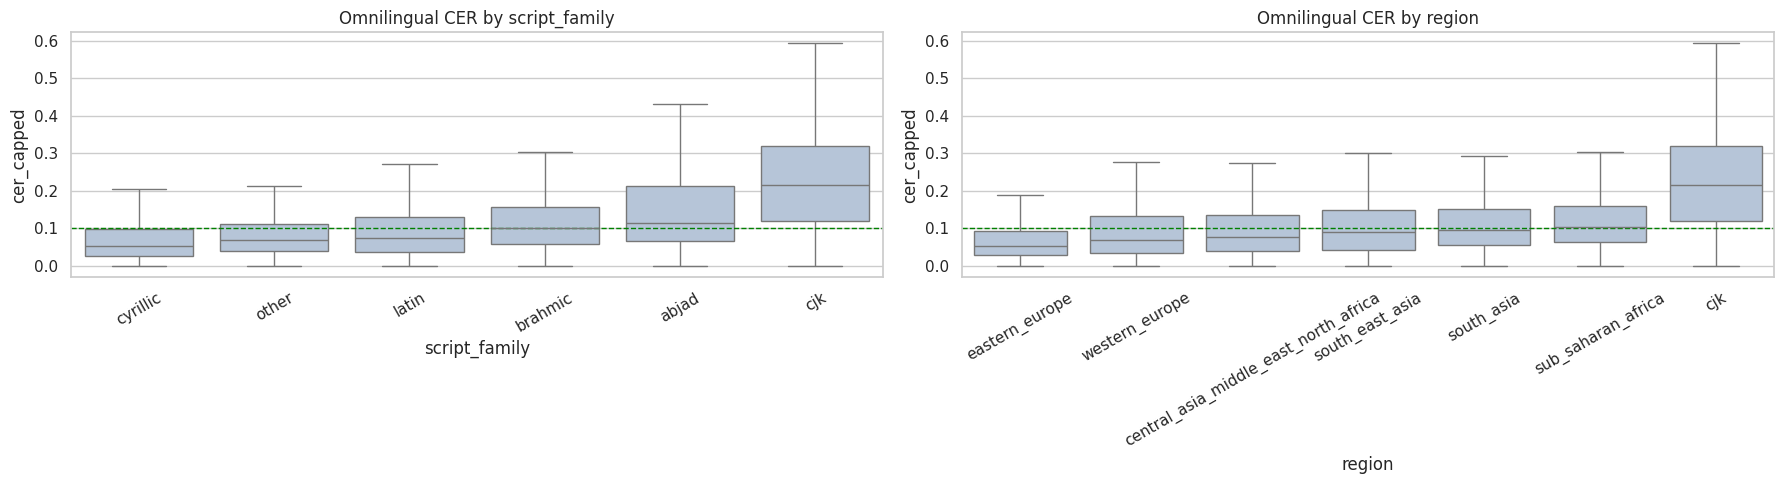

In [11]:
feat = pd.read_csv(FEATURES_PATH)
feat = feat[feat["model"] == "Omnilingual ASR CTC 300M"].drop(columns=["cer", "cer_capped", "failure", "hallucination"], errors="ignore")
script_cols = [c for c in feat.columns if c.startswith("script_family_")]
region_cols = [c for c in feat.columns if c.startswith("region_")]
feat["script_family"] = feat[script_cols].idxmax(axis=1).str.replace("script_family_", "", regex=False)
feat["region"] = feat[region_cols].idxmax(axis=1).str.replace("region_", "", regex=False)

data = baseline.merge(feat.drop(columns=["language", "sample_id"], errors="ignore"),
                      on=["language_code", "clip_pos"], how="inner")
print(f"Joined {len(data)} of {len(baseline)} transcriptions with the Avance 2 features")

def group_table(col):
    by_lang = data.groupby([col, "language"])["cer"].mean().reset_index()
    g = by_lang.groupby(col).agg(languages=("language", "size"), cer=("cer", "mean"),
                                 coverage=("cer", lambda s: (s <= QUALITY_CER).mean()))
    return g.assign(cer=(g.cer * 100).round(1), coverage=(g.coverage * 100).round(0)).sort_values("cer")

print("CER (%) and coverage (% of languages with CER <= 10%) by script family:"); display(group_table("script_family"))
print("By region:"); display(group_table("region"))

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, col in zip(axes, ["script_family", "region"]):
    order = data.groupby(col)["cer_capped"].median().sort_values().index
    sns.boxplot(data=data, x=col, y="cer_capped", order=order, ax=ax, showfliers=False, color="lightsteelblue")
    ax.axhline(QUALITY_CER, ls="--", c="green", lw=1)
    ax.set_title(f"Omnilingual CER by {col}")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretación de la línea base de voz.**

- **La implementación está validada.** El CER promedio por idioma (11.4%) coincide con el publicado para este modelo en FLEURS (11.8%), y el CER total es prácticamente igual al de la evaluación del Avance 1. Esto confirma que la versión de `transformers` se comporta como el modelo oficial y que la medición es correcta. **La línea base de voz cumple el criterio de aceptación.**
- **Solo la mitad de los idiomas alcanza calidad aceptable.** El 53% de los idiomas tiene CER ≤ 10%. Esta cobertura es la cifra principal que los siguientes modelos deben mejorar.
- **La desigualdad es considerable.** El Gini es 0.30 y el peor idioma tiene un error casi 20 veces mayor que el mejor (español, 3.6%). El peor es el urdu (70.8%), por el problema de alfabeto ya descrito; sin él, los peores son cantonés (31.1%), irlandés (30.4%), lao (26.3%) y japonés (24.5%).
- **El error sigue el patrón que CLEAR busca medir.** Los idiomas de Europa del Este y de escritura cirílica tienen el menor error (7.0% y 7.4%) y casi todos alcanzan la calidad. En cambio, ningún idioma CJK la alcanza (22.7%), las escrituras abjad (árabe, hebreo, persa, urdu y otras) promedian 21.5%, y en África subsahariana y el sur de Asia solo uno de cada tres idiomas llega a CER ≤ 10%.

## 6. Línea base predictiva

- **Objetivo:** `cer_capped` de cada grabación (CER acotado a 100%).
- **Características:** las seleccionadas en el Avance 2. Se excluyen las columnas `model_*` (aquí solo hay un modelo) y `language_difficulty_pc1`, porque se calculó con el CER de los propios modelos y sería una fuga de información (*data leakage*).
- **Métricas del modelo predictivo:**
  - **MAE** (error absoluto medio), métrica principal. Está en las mismas unidades que el CER: un MAE de 0.05 significa que la predicción se equivoca, en promedio, por 5 puntos de CER. Es robusta a la cola larga de errores extremos.
  - **RMSE**, que castiga más los errores grandes; si es mucho mayor que el MAE, el modelo falla mucho en pocos casos.
  - **R²**, la proporción de la variación del CER que explica el modelo. 0 equivale al modelo nulo; un valor negativo, peor que el nulo.

In [12]:
from sklearn.model_selection import GroupKFold, cross_validate, cross_val_predict, learning_curve, validation_curve, permutation_test_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

EXCLUDE = {"language_code", "language", "clip_pos", "sample_id", "model", "language_difficulty_pc1", "script_family", "region"}
FEATURES = [c for c in feat.columns if c not in EXCLUDE and not c.startswith("model_")]
FEATURES = [c for c in FEATURES if data[c].nunique() > 1]
print(f"{len(FEATURES)} features:", FEATURES)

X = data[FEATURES].fillna(0).astype(float)
y = data["cer_capped"].values
groups = data["language_code"].values
cv_splits = list(GroupKFold(n_splits=5).split(X, y, groups))

def make_rf(n_estimators=200, max_depth=8):
    return RandomForestRegressor(n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=20,
                                 random_state=RANDOM_STATE, n_jobs=-1)

models = {"Dummy (mean)": DummyRegressor(strategy="mean"), "Ridge": Ridge(alpha=1.0), "Random Forest": make_rf()}
scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

rows, fold_mae = [], {}
for name, model in models.items():
    res = cross_validate(model, X, y, cv=cv_splits, scoring=scoring, return_train_score=True)
    fold_mae[name] = -res["test_MAE"]
    rows.append({"model": name,
                 "MAE_train": -res["train_MAE"].mean(), "MAE_test": -res["test_MAE"].mean(),
                 "RMSE_train": -res["train_RMSE"].mean(), "RMSE_test": -res["test_RMSE"].mean(),
                 "R2_train": res["train_R2"].mean(), "R2_test": res["test_R2"].mean(),
                 "R2_test_std": res["test_R2"].std()})
cv_results = pd.DataFrame(rows).set_index("model")
print("5-fold GroupKFold by language (test = languages never seen in training):")
display(cv_results.round(4))
print("Test MAE per fold:")
display(pd.DataFrame(fold_mae, index=[f"fold {i + 1}" for i in range(5)]).round(4))

21 features: ['duration_s_z', 'silence_ratio_z', 'zcr_z', 'ref_chars_z', 'ref_words_z', 'speech_rate_z', 'log_speakers_z', 'script_family_abjad', 'script_family_brahmic', 'script_family_cjk', 'script_family_cyrillic', 'script_family_latin', 'script_family_other', 'region_central_asia_middle_east_north_africa', 'region_cjk', 'region_eastern_europe', 'region_south_asia', 'region_south_east_asia', 'region_sub_saharan_africa', 'region_western_europe', 'no_space_lang']
5-fold GroupKFold by language (test = languages never seen in training):


,MAE_train,MAE_test,RMSE_train,RMSE_test,R2_train,R2_test,R2_test_std
model,,,,,,,
Dummy (mean),0.0768,0.0775,0.1233,0.1202,0.0000,-0.0624,0.0896
Ridge,0.0676,0.0762,0.1070,0.1203,0.2445,-0.0615,0.1859
Random Forest,0.0564,0.0844,0.0907,0.1394,0.4545,-0.6634,0.8641


Test MAE per fold:


,Dummy (mean),Ridge,Random Forest
fold 1,0.0633,0.0510,0.0733
fold 2,0.0842,0.0765,0.0810
fold 3,0.0941,0.0903,0.0915
fold 4,0.0751,0.0780,0.0734
fold 5,0.0710,0.0851,0.1026


### 6.1 ¿Cuánto del error depende del idioma?

Antes de juzgar los modelos conviene saber cuánto podrían explicar como máximo. Se descompone la varianza del CER en la parte **entre idiomas** (diferencias entre el promedio de cada idioma) y la parte **dentro de cada idioma** (diferencias entre los 50 audios de un mismo idioma). Las características del idioma (escritura, región, hablantes) solo pueden explicar la primera; la segunda depende del audio y del texto de cada grabación.

In [13]:
lang_mean = data.groupby("language_code")["cer_capped"].transform("mean")
total_var = ((data["cer_capped"] - data["cer_capped"].mean()) ** 2).sum()
between = ((lang_mean - data["cer_capped"].mean()) ** 2).sum() / total_var
print(f"Share of CER variance between languages: {between:.1%}")
print(f"Share of CER variance within languages (between recordings): {1 - between:.1%}")

Share of CER variance between languages: 42.5%
Share of CER variance within languages (between recordings): 57.5%


**Lectura.** El porcentaje entre idiomas es el R² máximo que podría alcanzar un modelo que conociera perfectamente cada idioma pero nada de cada grabación. Las características del idioma (escritura, región, hablantes) solo pueden aspirar a esa parte, y además deben generalizar a idiomas que el modelo nunca vio. Ese es el techo contra el que deben leerse los resultados siguientes; la parte dentro de cada idioma depende del hablante, del ruido y del contenido de cada frase, que las características del Avance 2 apenas describen.

### 6.2 Comparación entre entrenamiento y prueba

La tabla anterior es la primera prueba de sub/sobreajuste:

- **Sobreajuste:** el error de entrenamiento es mucho menor que el de prueba (R² de entrenamiento alto y R² de prueba bajo). El modelo memorizó los idiomas que vio.
- **Subajuste:** ambos errores son altos y parecidos entre sí, y cercanos al modelo nulo. El modelo es demasiado simple o las características no tienen información suficiente.
- **Buen ajuste:** ambos errores son bajos y parecidos.

La celda siguiente aplica estos criterios a los números de esta ejecución.

In [14]:
best = cv_results.drop("Dummy (mean)")["MAE_test"].idxmin()
dummy_mae = cv_results.loc["Dummy (mean)", "MAE_test"]
for name in ["Ridge", "Random Forest"]:
    r = cv_results.loc[name]
    gain = 1 - r["MAE_test"] / dummy_mae
    gap = r["R2_train"] - r["R2_test"]
    if r["R2_train"] < 0.30 and r["R2_test"] < 0.05:
        diagnosis = "underfitting: low R2 even on training data and no gain on unseen languages"
    elif gap > 0.15:
        diagnosis = "overfitting: train R2 is much higher than test R2"
    elif r["R2_test"] < 0.05:
        diagnosis = "underfitting: close to the mean-only model on unseen languages"
    else:
        diagnosis = "no strong sign of over- or underfitting"
    folds_better = (fold_mae[name] < fold_mae["Dummy (mean)"]).sum()
    print(f"{name}: test MAE {r['MAE_test']:.4f} ({gain:+.1%} vs mean-only), R2 train {r['R2_train']:.3f} / test {r['R2_test']:.3f}"
          f" -> {diagnosis}. Beats the mean-only model in {folds_better} of 5 folds.")
print(f"\nBest model on unseen languages: {best}")

Ridge: test MAE 0.0762 (+1.8% vs mean-only), R2 train 0.245 / test -0.062 -> underfitting: low R2 even on training data and no gain on unseen languages. Beats the mean-only model in 3 of 5 folds.
Random Forest: test MAE 0.0844 (-8.8% vs mean-only), R2 train 0.455 / test -0.663 -> overfitting: train R2 is much higher than test R2. Beats the mean-only model in 3 of 5 folds.

Best model on unseen languages: Ridge


**Lectura de los resultados.**

- **Ridge subajusta.** Incluso en entrenamiento solo explica el 24% de la variación (R² = 0.24), y en idiomas no vistos su R² es −0.06, igual que el modelo nulo. Su MAE (0.0762) es apenas 1.8% mejor que predecir siempre el promedio (0.0775), y solo le gana en 3 de las 5 particiones. Un modelo lineal no alcanza a representar el problema con estas características.
- **El Random Forest de profundidad 8 sobreajusta.** En entrenamiento explica el 45% (R² = 0.45), pero en idiomas no vistos su R² cae a −0.66 y su MAE es 8.8% **peor** que el del modelo nulo. La variación entre particiones es muy grande (desviación de 0.86 en R²): aprendió rasgos de los idiomas que vio que no se repiten en otros.
- **Conclusión.** Un modelo simple no capta el patrón y uno complejo memoriza idiomas. Las secciones 7 y 8 buscan el punto intermedio ajustando la complejidad y quitando características irrelevantes.

### 6.3 ¿Es mejor que el azar? Prueba de permutación

Se revuelve el CER entre todas las grabaciones, se reentrena el mejor modelo y se mide su MAE; se repite 100 veces. Si el MAE con los datos reales es mejor que el de casi todas las versiones revueltas (valor p < 0.05), el modelo encontró una relación real entre las características y el error, y no una coincidencia. Con 100 permutaciones, el valor p más pequeño posible es 1/101 ≈ 0.01.

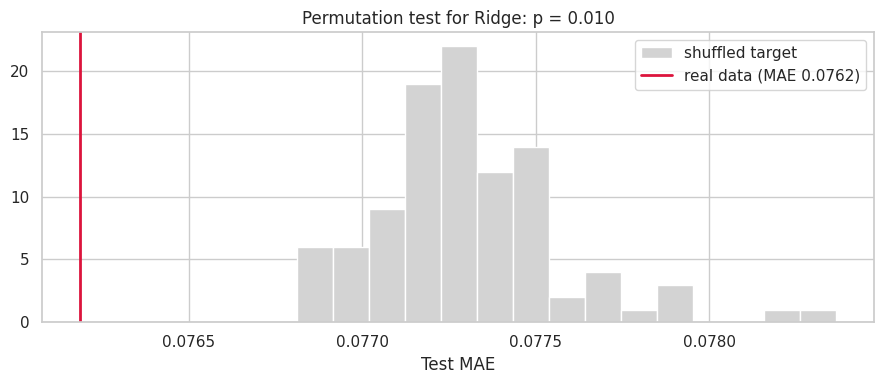

Real MAE 0.0762 vs shuffled MAE 0.0773 ± 0.0003; p = 0.010
Better than chance


In [15]:
best_model = Ridge(alpha=1.0) if best == "Ridge" else make_rf(n_estimators=100)
score, perm_scores, p_value = permutation_test_score(best_model, X, y, cv=cv_splits, n_permutations=100,
                                                     scoring="neg_mean_absolute_error", random_state=RANDOM_STATE, n_jobs=-1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(-perm_scores, bins=15, color="lightgray", label="shuffled target")
ax.axvline(-score, c="crimson", lw=2, label=f"real data (MAE {-score:.4f})")
ax.set_xlabel("Test MAE")
ax.set_title(f"Permutation test for {best}: p = {p_value:.3f}")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Real MAE {-score:.4f} vs shuffled MAE {(-perm_scores).mean():.4f} ± {perm_scores.std():.4f}; p = {p_value:.3f}")
print("Better than chance" if p_value < 0.05 else "Not distinguishable from chance")

## 7. Diagnóstico de sub/sobreajuste

Tres herramientas complementan la comparación entre entrenamiento y prueba (Géron, 2022, cap. 4):

1. **Curva de aprendizaje:** error de entrenamiento y de validación conforme crece el número de grabaciones. Si las curvas se juntan en un error alto, hay subajuste y más datos no ayudarán; si quedan separadas, hay sobreajuste y más datos sí ayudarían.
2. **Curva de validación:** error según la profundidad máxima de los árboles del Random Forest. A la izquierda el modelo es demasiado simple (subajuste); a la derecha, demasiado complejo (sobreajuste). Si el mínimo del error de validación cae en una profundidad menor que la usada (8), el Random Forest está sobreajustando y conviene reducirla (sección 7.1).
3. **Residuos:** diferencia entre el CER real y el predicho en idiomas no vistos. Un patrón (por ejemplo, residuos grandes en los errores altos) indica qué parte del problema no capta el modelo.

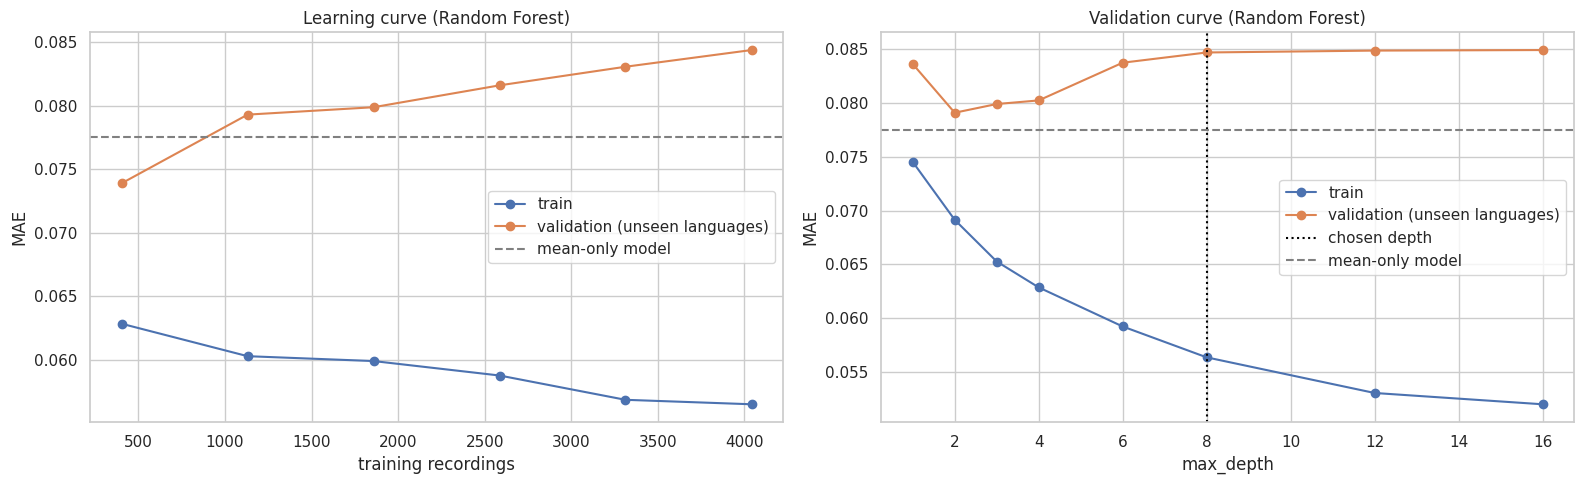

Final gap between validation and train MAE in the learning curve: 0.0278
Depth with the lowest validation MAE: 2


In [16]:
train_sizes, lc_train, lc_test = learning_curve(make_rf(n_estimators=100), X, y, cv=cv_splits,
                                                train_sizes=np.linspace(0.1, 1.0, 6), scoring="neg_mean_absolute_error",
                                                shuffle=True, random_state=RANDOM_STATE, n_jobs=-1)
depths = [1, 2, 3, 4, 6, 8, 12, 16]
vc_train, vc_test = validation_curve(make_rf(n_estimators=100), X, y, param_name="max_depth", param_range=depths,
                                     cv=cv_splits, scoring="neg_mean_absolute_error", n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(train_sizes, -lc_train.mean(axis=1), "o-", label="train")
axes[0].plot(train_sizes, -lc_test.mean(axis=1), "o-", label="validation (unseen languages)")
axes[0].axhline(dummy_mae, ls="--", c="gray", label="mean-only model")
axes[0].set_xlabel("training recordings"); axes[0].set_ylabel("MAE"); axes[0].set_title("Learning curve (Random Forest)")
axes[0].legend()
axes[1].plot(depths, -vc_train.mean(axis=1), "o-", label="train")
axes[1].plot(depths, -vc_test.mean(axis=1), "o-", label="validation (unseen languages)")
axes[1].axvline(8, ls=":", c="black", label="chosen depth")
axes[1].axhline(dummy_mae, ls="--", c="gray", label="mean-only model")
axes[1].set_xlabel("max_depth"); axes[1].set_ylabel("MAE"); axes[1].set_title("Validation curve (Random Forest)")
axes[1].legend()
plt.tight_layout()
plt.show()

best_depth = depths[int(np.argmin(-vc_test.mean(axis=1)))]
print(f"Final gap between validation and train MAE in the learning curve: {(-lc_test.mean(axis=1))[-1] - (-lc_train.mean(axis=1))[-1]:.4f}")
print(f"Depth with the lowest validation MAE: {best_depth}")

**Lectura de las curvas.**

- **Curva de aprendizaje.** El error de entrenamiento baja de 0.063 a 0.057 conforme se agregan grabaciones, pero el de validación **sube** de 0.074 a 0.084, y a partir de unas 1,000 grabaciones queda por encima del modelo nulo (línea gris). La brecha final es de 0.028. Es la firma del sobreajuste por idioma: cada grabación nueva viene de un idioma que el bosque aprende a reconocer, lo que mejora el entrenamiento y empeora la predicción en idiomas nuevos. Más grabaciones de los mismos idiomas no resolverían el problema.
- **Curva de validación.** El error de entrenamiento baja sin parar al aumentar la profundidad (de 0.074 a 0.052), mientras que el de validación tiene su mínimo con profundidad 2 (0.079) y luego sube. La profundidad 8 que se usó estaba claramente en la zona de sobreajuste. Aun así, ninguna profundidad baja el error de validación por debajo del modelo nulo (0.0775).

### 7.1 Corrección del sobreajuste

Se reentrena el Random Forest con la profundidad que minimiza el error de validación y se compara con la versión original (profundidad 8). Si el sobreajuste era la causa, la brecha entre entrenamiento y prueba debe reducirse.

In [17]:
def evaluate(model, cols, label):
    res = cross_validate(model, X[cols], y, cv=cv_splits, scoring=scoring, return_train_score=True)
    return {"model": label, "features": len(cols),
            "MAE_train": -res["train_MAE"].mean(), "MAE_test": -res["test_MAE"].mean(),
            "R2_train": res["train_R2"].mean(), "R2_test": res["test_R2"].mean(),
            "gain_vs_mean_only": 1 + res["test_MAE"].mean() / dummy_mae}

tuned = pd.DataFrame([
    evaluate(DummyRegressor(strategy="mean"), FEATURES, "Dummy (mean)"),
    evaluate(make_rf(max_depth=8), FEATURES, "Random Forest, depth 8"),
    evaluate(make_rf(max_depth=best_depth), FEATURES, f"Random Forest, depth {best_depth}"),
    evaluate(Ridge(alpha=1.0), FEATURES, "Ridge"),
]).set_index("model")
display(tuned.round(4))
r8, rb = tuned.loc["Random Forest, depth 8"], tuned.loc[f"Random Forest, depth {best_depth}"]
print(f"Train-test R2 gap: depth 8 = {r8['R2_train'] - r8['R2_test']:.3f} -> depth {best_depth} = {rb['R2_train'] - rb['R2_test']:.3f}")

,features,MAE_train,MAE_test,R2_train,R2_test,gain_vs_mean_only
model,,,,,,
Dummy (mean),21,0.0768,0.0775,0.0000,-0.0624,0.0000
"Random Forest, depth 8",21,0.0564,0.0844,0.4545,-0.6634,-0.0881
"Random Forest, depth 2",21,0.0692,0.0790,0.2511,-0.3819,-0.0187
Ridge,21,0.0676,0.0762,0.2445,-0.0615,0.0175


Train-test R2 gap: depth 8 = 1.118 -> depth 2 = 0.633


**Lectura.** Con profundidad 2, la brecha de R² entre entrenamiento y prueba se reduce de 1.12 a 0.63 y el MAE de prueba mejora de 0.0844 a 0.0790. Reducir la complejidad corrige buena parte del sobreajuste, pero el bosque sigue 1.9% peor que el modelo nulo. Ridge sigue siendo el mejor modelo (MAE 0.0762). El problema no es solo de complejidad: las características no tienen suficiente información sobre idiomas nuevos.

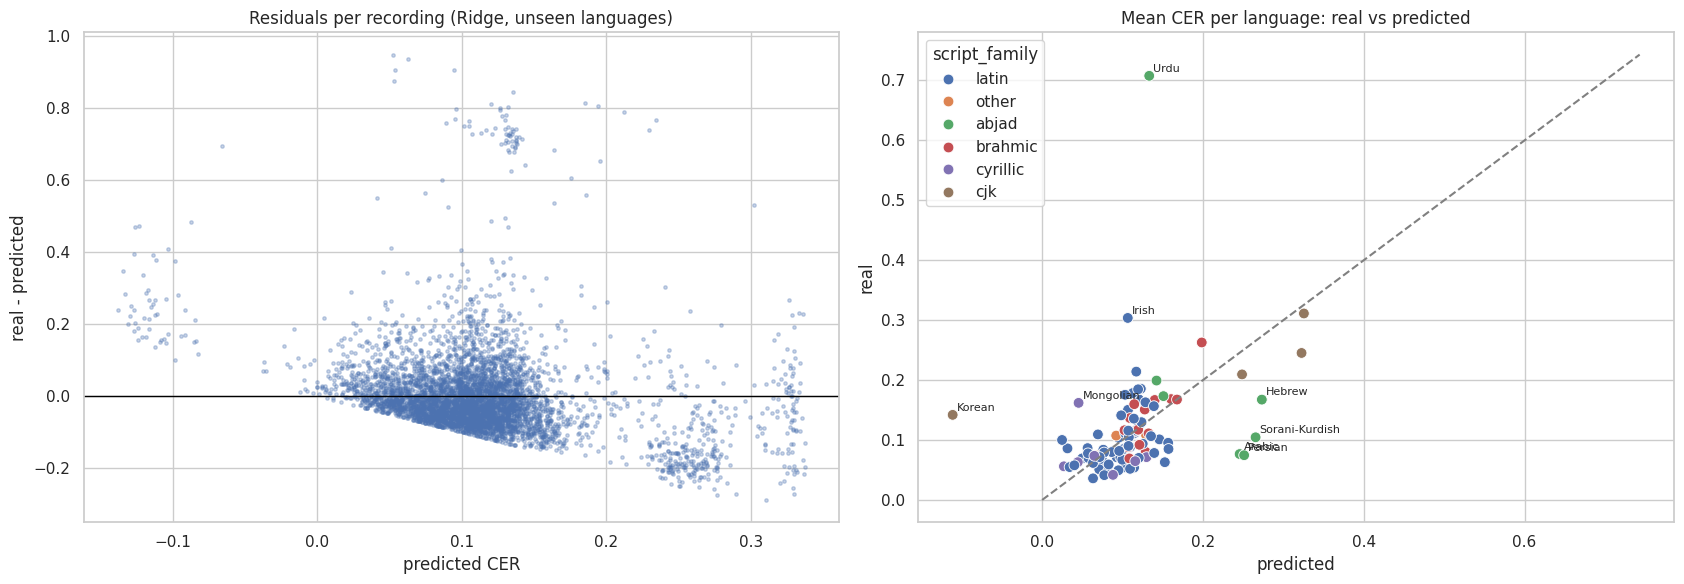

Ranking of languages by difficulty: Spearman rho between predicted and real mean CER = 0.54 (p = 3.6e-09)


In [18]:
best_for_pred = Ridge(alpha=1.0) if best == "Ridge" else make_rf()
data["cer_pred"] = cross_val_predict(best_for_pred, X, y, cv=cv_splits, n_jobs=-1)
data["residual"] = data["cer_capped"] - data["cer_pred"]
lang_pred = data.groupby("language").agg(real=("cer_capped", "mean"), predicted=("cer_pred", "mean"),
                                         script_family=("script_family", "first")).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
axes[0].scatter(data["cer_pred"], data["residual"], s=6, alpha=0.3)
axes[0].axhline(0, c="black", lw=1)
axes[0].set_xlabel("predicted CER"); axes[0].set_ylabel("real - predicted")
axes[0].set_title(f"Residuals per recording ({best}, unseen languages)")
sns.scatterplot(data=lang_pred, x="predicted", y="real", hue="script_family", s=60, ax=axes[1])
lim = [0, max(lang_pred["real"].max(), lang_pred["predicted"].max()) * 1.05]
axes[1].plot(lim, lim, "--", c="gray")
for _, r in lang_pred.assign(err=(lang_pred.real - lang_pred.predicted).abs()).nlargest(8, "err").iterrows():
    axes[1].annotate(r["language"], (r["predicted"], r["real"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[1].set_title("Mean CER per language: real vs predicted")
plt.tight_layout()
plt.show()

rho, p = stats.spearmanr(lang_pred["predicted"], lang_pred["real"])
print(f"Ranking of languages by difficulty: Spearman rho between predicted and real mean CER = {rho:.2f} (p = {p:.3g})")

**Lectura de los residuos.**

- **Las predicciones están comprimidas.** Ridge predice casi todo entre 0 y 0.2, cerca del promedio, mientras que el CER real llega hasta 1. Por eso hay residuos positivos grandes (de 0.6 a 0.9): son grabaciones con errores muy altos que ningún rasgo del idioma anticipa, la mayoría del urdu.
- **El urdu contamina la característica de escritura abjad.** Como el urdu tiene un CER de 71% por el problema de alfabeto, el modelo aprende que "escritura abjad = error alto". Por eso sobreestima el error del árabe, el persa, el kurdo sorani y el hebreo (predice alrededor de 25% y su error real está entre 8% y 17%): son los residuos negativos del extremo derecho. Es un efecto de la medición, no del reconocimiento.
- **Ridge puede predecir valores imposibles.** Para el coreano predice un CER negativo (−11%), porque combina coeficientes de la región CJK y de idiomas con espacios. Es una limitación conocida de los modelos lineales sobre una variable acotada.
- **Aun así, el orden de los idiomas es razonable.** La correlación de Spearman entre el CER real y el predicho por idioma es 0.54: el modelo distingue moderadamente los idiomas fáciles de los difíciles, aunque no acierte el valor.

## 8. Características importantes

Se usan tres métodos, para no depender de uno solo:

1. **Embebido, lineal:** coeficientes de Ridge. Como las características numéricas están estandarizadas, un coeficiente positivo grande indica que esa característica sube el error.
2. **Embebido, árboles:** importancia del Random Forest (reducción de la impureza en cada división).
3. **Por permutación (agnóstico al modelo):** se revuelve una característica en los idiomas de prueba y se mide cuánto empeora el MAE. Es la más confiable, porque se mide en datos no vistos.

Además se hace una **ablación por grupos** (método *wrapper*): se quita un grupo completo de características (audio, texto, escritura, región, hablantes, espacios), se reentrena y se mide cuánto empeora el error. Las variables de un mismo grupo (por ejemplo, las siete columnas de región) se evalúan juntas, porque por separado se reparten la importancia y parecen menos relevantes de lo que son.

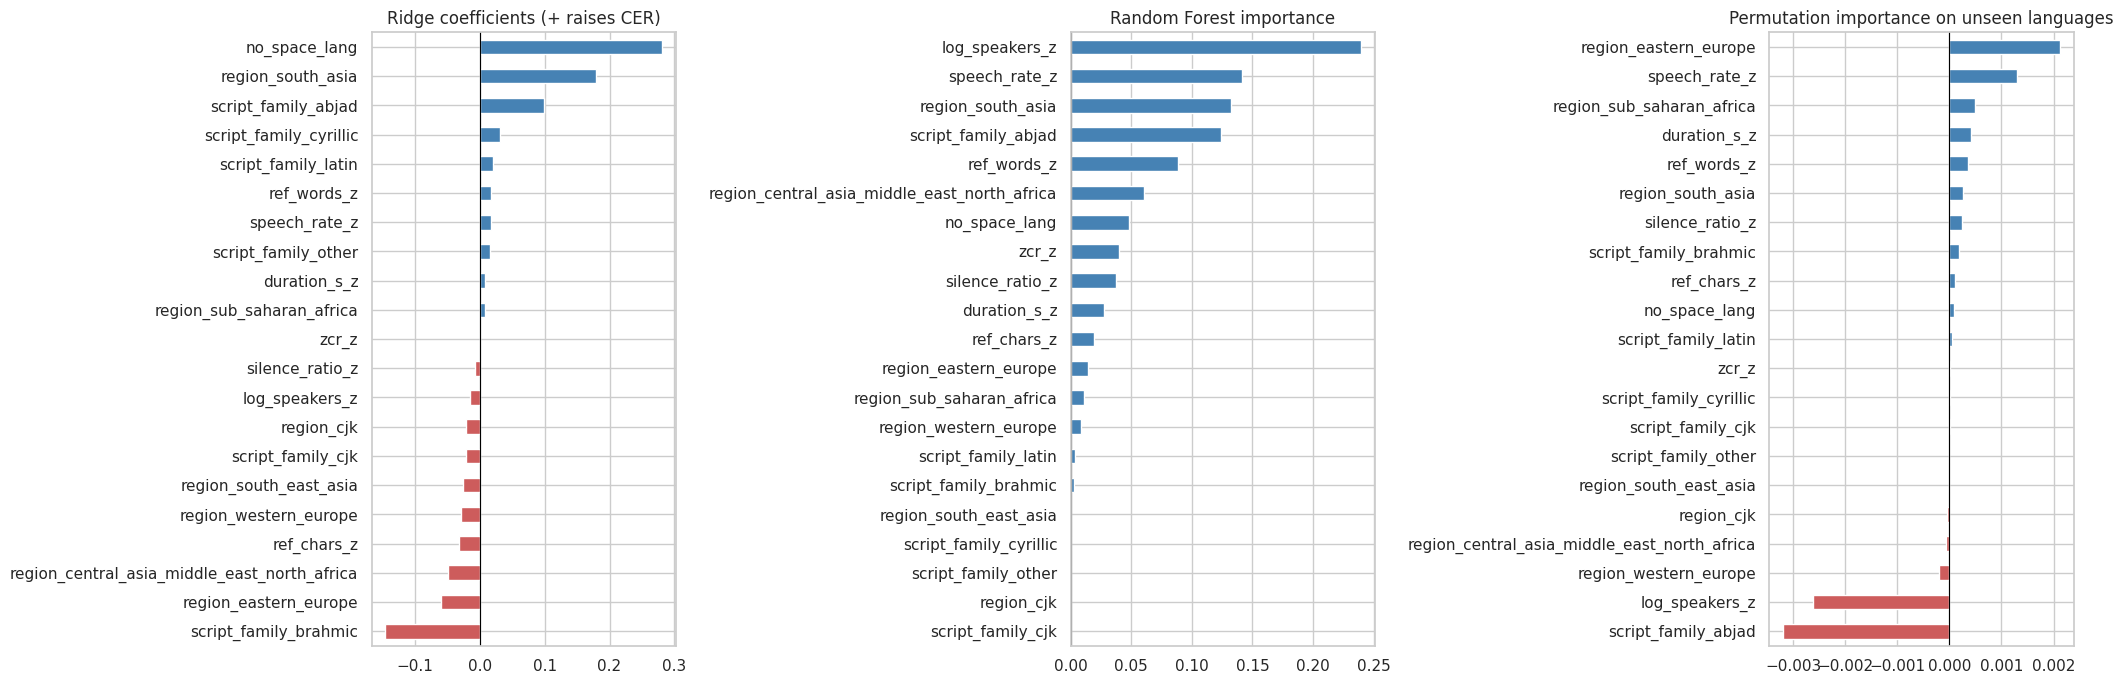

,ridge_coef,rf_importance,permutation_mae_increase
region_eastern_europe,-0.0603,0.0142,0.0021
speech_rate_z,0.0168,0.1414,0.0013
region_sub_saharan_africa,0.0076,0.0113,0.0005
duration_s_z,0.0085,0.0272,0.0004
ref_words_z,0.0169,0.0883,0.0004
region_south_asia,0.1785,0.1325,0.0003
silence_ratio_z,-0.0070,0.0375,0.0002
script_family_brahmic,-0.1457,0.0032,0.0002
ref_chars_z,-0.0325,0.0196,0.0001
no_space_lang,0.2813,0.0484,0.0001


In [19]:
ridge = Ridge(alpha=1.0).fit(X, y)
rf = make_rf().fit(X, y)

perm = np.zeros(len(FEATURES))
for tr, te in cv_splits:
    m = make_rf().fit(X.iloc[tr], y[tr])
    perm += permutation_importance(m, X.iloc[te], y[te], scoring="neg_mean_absolute_error", n_repeats=5,
                                   random_state=RANDOM_STATE, n_jobs=-1).importances_mean
perm /= len(cv_splits)

importance = pd.DataFrame({"ridge_coef": ridge.coef_, "rf_importance": rf.feature_importances_,
                           "permutation_mae_increase": perm}, index=FEATURES)
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, col, title in [(axes[0], "ridge_coef", "Ridge coefficients (+ raises CER)"),
                       (axes[1], "rf_importance", "Random Forest importance"),
                       (axes[2], "permutation_mae_increase", "Permutation importance on unseen languages")]:
    s = importance[col].sort_values()
    s.plot(kind="barh", ax=ax, color=["indianred" if v < 0 else "steelblue" for v in s])
    ax.axvline(0, c="black", lw=0.8)
    ax.set_title(title)
plt.tight_layout()
plt.show()
display(importance.sort_values("permutation_mae_increase", ascending=False).round(4))

**Lectura de las tres gráficas.**

- **Ridge** asigna los coeficientes más grandes a `no_space_lang` (+0.28: los idiomas sin espacios tienen más error), a `region_south_asia` (+0.18) y a `script_family_abjad` (+0.10). `script_family_brahmic` tiene un coeficiente negativo (−0.15) que compensa en parte al del sur de Asia, porque casi todos los idiomas brahmicos son de esa región.
- **El Random Forest** se apoya sobre todo en `log_speakers_z` (0.24), `speech_rate_z` (0.14), `region_south_asia` (0.13) y `script_family_abjad` (0.12).
- **La importancia por permutación contradice al Random Forest en dos casos.** Al revolver `log_speakers_z` y `script_family_abjad` en idiomas no vistos, el error **baja** (−0.0026 y −0.0032). El bosque las usa para reconocer idiomas que ya vio: el número de hablantes es casi un identificador del idioma, porque cada idioma tiene un valor distinto. Esto explica su sobreajuste.
- **Lo que sí generaliza** son señales pequeñas: pertenecer a Europa del Este (menos error), la velocidad de habla y la región de África subsahariana.

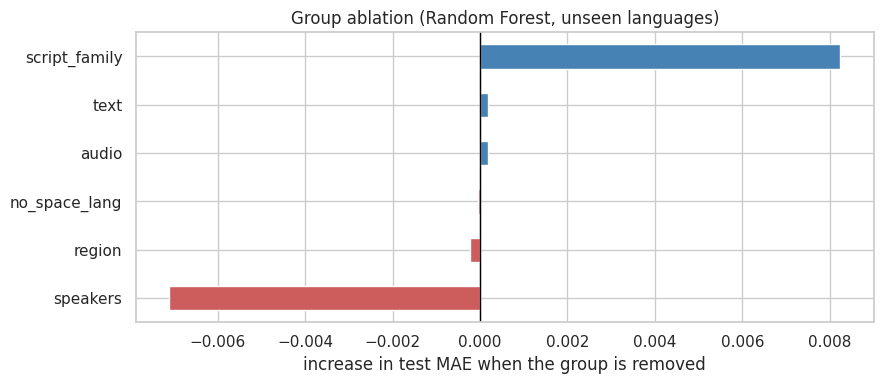

MAE with all features: 0.0847
  without script_family  MAE changes by +0.0082 -> useful
  without text           MAE changes by +0.0002 -> no measurable effect
  without audio          MAE changes by +0.0002 -> no measurable effect
  without no_space_lang  MAE changes by -0.0001 -> no measurable effect
  without region         MAE changes by -0.0002 -> no measurable effect
  without speakers       MAE changes by -0.0071 -> adds noise


In [20]:
FEATURE_GROUPS = {
    "audio": [c for c in FEATURES if c in {"duration_s_z", "silence_ratio_z", "zcr_z", "rms_db_z", "peak_amplitude_z"}],
    "text": [c for c in FEATURES if c in {"ref_chars_z", "ref_words_z", "speech_rate_z"}],
    "script_family": [c for c in FEATURES if c.startswith("script_family_")],
    "region": [c for c in FEATURES if c.startswith("region_")],
    "speakers": [c for c in FEATURES if c == "log_speakers_z"],
    "no_space_lang": [c for c in FEATURES if c == "no_space_lang"],
}
FEATURE_GROUPS = {k: v for k, v in FEATURE_GROUPS.items() if v}

def cv_mae(cols):
    res = cross_validate(make_rf(n_estimators=100), X[cols], y, cv=cv_splits, scoring="neg_mean_absolute_error", n_jobs=-1)
    return -res["test_score"].mean()

full_mae = cv_mae(FEATURES)
ablation = pd.Series({g: cv_mae([c for c in FEATURES if c not in cols]) - full_mae for g, cols in FEATURE_GROUPS.items()})
ablation = ablation.sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ablation.plot(kind="barh", ax=ax, color=["indianred" if v < 0 else "steelblue" for v in ablation])
ax.axvline(0, c="black", lw=1)
ax.set_xlabel("increase in test MAE when the group is removed")
ax.set_title("Group ablation (Random Forest, unseen languages)")
plt.tight_layout()
plt.show()
print(f"MAE with all features: {full_mae:.4f}")
for g, v in ablation.sort_values(ascending=False).items():
    effect = "useful" if v > 0.0005 else ("adds noise" if v < -0.0005 else "no measurable effect")
    print(f"  without {g:<14} MAE changes by {v:+.4f} -> {effect}")

**Lectura de la ablación.** Solo un grupo es claramente útil: la **familia de escritura**, cuya eliminación empeora el MAE en 0.0082. El número de **hablantes** agrega ruido: quitarlo **mejora** el MAE en 0.0071, lo que confirma que el modelo lo usa para memorizar idiomas. Audio, texto, región e idioma sin espacios no tienen un efecto medible por sí solos.

### 8.1 Modelo con características reducidas

Las instrucciones del avance advierten que las características irrelevantes pueden empeorar el modelo. Se prueba esa hipótesis: se quitan los grupos que la ablación marcó como ruido y se reentrenan Ridge y el Random Forest con la profundidad corregida. Se comparan dos conjuntos: todas las características menos las que agregan ruido, y solo los grupos útiles.

Groups removed as noise: ['speakers']
Useful groups: ['script_family']


,features,MAE_train,MAE_test,R2_train,R2_test,gain_vs_mean_only
model,,,,,,
Dummy (mean),21,0.0768,0.0775,0.0000,-0.0624,0.0000
"Ridge, all features",21,0.0676,0.0762,0.2445,-0.0615,0.0175
"Ridge, without noise groups",20,0.0688,0.0770,0.2318,-0.0955,0.0073
"Ridge, useful groups only",6,0.0732,0.0810,0.1174,-0.2472,-0.0444
"Random Forest depth 2, all features",21,0.0692,0.0790,0.2511,-0.3819,-0.0187
"Random Forest depth 2, without noise groups",20,0.0700,0.0780,0.2269,-0.2035,-0.0060
"Random Forest depth 2, useful groups only",6,0.0738,0.0821,0.1068,-0.2817,-0.0589


Final predictive baseline: Ridge, all features
  test MAE 0.0762 vs mean-only 0.0775 (+1.8%), R2 train 0.245 / test -0.062


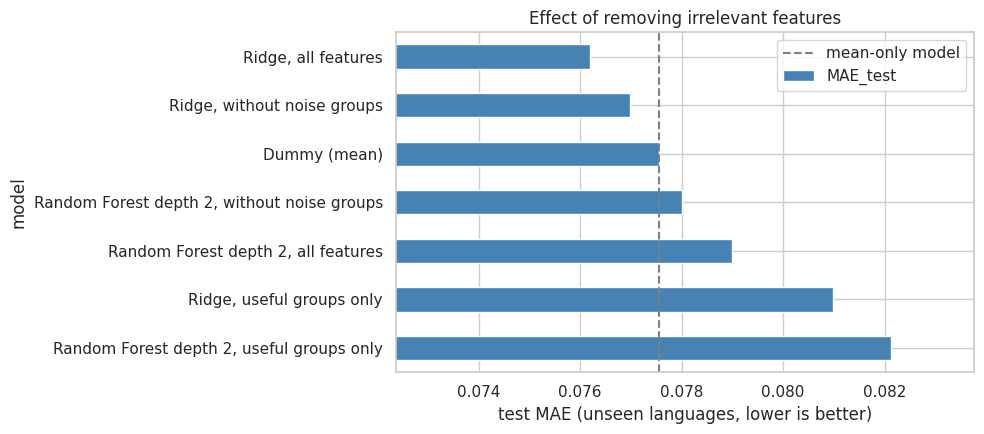

In [21]:
noise_groups = [g for g, v in ablation.items() if v < -0.0005]
useful_groups = [g for g, v in ablation.items() if v > 0.0005]
without_noise = [c for c in FEATURES if not any(c in FEATURE_GROUPS[g] for g in noise_groups)]
useful_only = [c for g in useful_groups for c in FEATURE_GROUPS[g]] or without_noise
print("Groups removed as noise:", noise_groups or "none")
print("Useful groups:", useful_groups or "none")

reduced = pd.DataFrame([
    evaluate(DummyRegressor(strategy="mean"), FEATURES, "Dummy (mean)"),
    evaluate(Ridge(alpha=1.0), FEATURES, "Ridge, all features"),
    evaluate(Ridge(alpha=1.0), without_noise, "Ridge, without noise groups"),
    evaluate(Ridge(alpha=1.0), useful_only, "Ridge, useful groups only"),
    evaluate(make_rf(max_depth=best_depth), FEATURES, f"Random Forest depth {best_depth}, all features"),
    evaluate(make_rf(max_depth=best_depth), without_noise, f"Random Forest depth {best_depth}, without noise groups"),
    evaluate(make_rf(max_depth=best_depth), useful_only, f"Random Forest depth {best_depth}, useful groups only"),
]).set_index("model")
display(reduced.round(4))

final_name = reduced.drop("Dummy (mean)")["MAE_test"].idxmin()
final = reduced.loc[final_name]
print(f"Final predictive baseline: {final_name}")
print(f"  test MAE {final['MAE_test']:.4f} vs mean-only {dummy_mae:.4f} ({final['gain_vs_mean_only']:+.1%}), R2 train {final['R2_train']:.3f} / test {final['R2_test']:.3f}")

fig, ax = plt.subplots(figsize=(10, 4.5))
reduced["MAE_test"].sort_values(ascending=False).plot(kind="barh", ax=ax, color="steelblue")
ax.axvline(dummy_mae, ls="--", c="gray", label="mean-only model")
ax.set_xlim(reduced["MAE_test"].min() * 0.95, reduced["MAE_test"].max() * 1.02)
ax.set_xlabel("test MAE (unseen languages, lower is better)")
ax.set_title("Effect of removing irrelevant features")
ax.legend()
plt.tight_layout()
plt.show()

**Lectura.**

- Quitar el número de hablantes **mejora** al Random Forest (MAE de 0.0790 a 0.0780), lo que confirma que lo usaba para memorizar idiomas. En Ridge el efecto es el contrario y pequeño (de 0.0762 a 0.0770): la regularización ya había reducido su coeficiente casi a cero (−0.016), así que no le hacía daño.
- Dejar solo la familia de escritura empeora a los dos modelos (MAE de 0.0810 y 0.0821). Aunque cada grupo por separado no tiene un efecto medible, en conjunto aportan información.
- **Modelo final:** Ridge con todas las características (MAE 0.0762, 1.8% mejor que el modelo nulo). Ningún subconjunto lo supera.

In [22]:
per_lang.assign(cer_pct=(per_lang.cer * 100).round(2), wer_pct=(per_lang.wer * 100).round(2)) \
    .to_csv(f"{OUTPUT_DIR}/avance3_omnilingual_by_language.csv", index=False, encoding="utf-8")
baseline.drop(columns=["ref_norm", "pred_norm"]).to_csv(f"{OUTPUT_DIR}/avance3_omnilingual_predictions.csv",
                                                        index=False, encoding="utf-8")
pd.concat([cv_results, tuned, reduced]).to_csv(f"{OUTPUT_DIR}/avance3_predictive_baseline_cv.csv", encoding="utf-8")

print("=" * 72)
print("AVANCE 3 BASELINE: KEY NUMBERS FROM THIS RUN")
print("=" * 72)
print(f"Omnilingual: {per_lang.shape[0]} languages, {len(baseline)} transcriptions")
print(f"  CER macro mean {lang_cer.mean():.1%} (paper: {PUBLISHED_CER}%) | median {lang_cer.median():.1%} | micro {summary.loc['micro (whole corpus)', 'CER']:.1f}%")
print(f"  WER macro mean {per_lang['wer'].mean():.1%} (languages with spaces)")
print(f"  Coverage CER <= 10%: {(lang_cer <= QUALITY_CER).mean():.1%} of languages | Gini {gini(lang_cer):.3f} | max/min {lang_cer.max() / lang_cer.min():.1f}x")
print(f"Share of CER variance between languages: {between:.1%}")
print(f"Predictive baseline: {final_name}, test MAE {final['MAE_test']:.4f} vs mean-only {dummy_mae:.4f}"
      f" ({final['gain_vs_mean_only']:+.1%}), R2 test {final['R2_test']:.3f} | permutation p ({best}, all features) = {p_value:.3f}")
print(f"  Most useful feature group: {ablation.idxmax()} | language ranking Spearman rho {rho:.2f}")
print(f"\nFiles saved in {OUTPUT_DIR}:")
print("  avance3_omnilingual_predictions.csv, avance3_omnilingual_by_language.csv, avance3_predictive_baseline_cv.csv")

AVANCE 3 BASELINE: KEY NUMBERS FROM THIS RUN
Omnilingual: 102 languages, 5087 transcriptions
  CER macro mean 11.4% (paper: 11.8%) | median 9.1% | micro 10.7%
  WER macro mean 36.9% (languages with spaces)
  Coverage CER <= 10%: 52.9% of languages | Gini 0.299 | max/min 19.6x
Share of CER variance between languages: 42.5%
Predictive baseline: Ridge, all features, test MAE 0.0762 vs mean-only 0.0775 (+1.8%), R2 test -0.062 | permutation p (Ridge, all features) = 0.010
  Most useful feature group: script_family | language ranking Spearman rho 0.54

Files saved in /content/drive/MyDrive/fleurs_results:
  avance3_omnilingual_predictions.csv, avance3_omnilingual_by_language.csv, avance3_predictive_baseline_cv.csv


## 9. Respuestas a las preguntas del avance

**¿Qué algoritmo se puede utilizar como baseline para predecir las variables objetivo?**
Para transcribir, **Omnilingual ASR CTC 300M**: los datos son audio (no estructurados) y solo hay 50 grabaciones por idioma, así que se necesita un modelo preentrenado; de los cuatro del estudio, es el único que cubre los 102 idiomas, el más pequeño y simple (CTC, sin modelo de lenguaje), no alucina y tiene una cifra publicada para validarlo (sección 2.1). Para predecir el error a partir de las características, **Ridge** y **Random Forest** de profundidad limitada: los datos son tabulares, hay solo 102 idiomas independientes y CLEAR necesita entender por qué falla cada idioma (sección 2.2).

**¿Se puede determinar la importancia de las características?**
Sí. Se usaron coeficientes de Ridge, importancia del Random Forest, importancia por permutación en idiomas no vistos y una ablación por grupos, cada uno con su gráfica (sección 8). La **familia de escritura** es el único grupo claramente útil. El **número de hablantes** resulta contraproducente: el Random Forest lo trata como su característica más importante, pero al quitarlo el error en idiomas nuevos baja, porque funciona como identificador del idioma y lleva al modelo a memorizar. Al quitarlo, el Random Forest mejora, lo que confirma que es irrelevante para predecir idiomas nuevos; dejar solo la familia de escritura, en cambio, empeora a los dos modelos (sección 8.1).

**¿El modelo está sub/sobreajustando?**
Ambos casos aparecen, según la complejidad (secciones 6.2 y 7). **Ridge subajusta**: explica solo el 24% de la variación en entrenamiento y nada en idiomas nuevos. **El Random Forest de profundidad 8 sobreajusta**: explica el 45% en entrenamiento y en idiomas nuevos es peor que el modelo nulo. La curva de aprendizaje lo confirma: al agregar grabaciones, el error de entrenamiento baja y el de validación sube. La curva de validación ubica el mejor punto en profundidad 2; con ella, la brecha de R² baja de 1.12 a 0.63 (sección 7.1), pero el bosque sigue sin superar al modelo nulo.

**¿Cuál es la métrica adecuada para este problema de negocio?**
El **CER promediado por idioma** (sección 4). Significa lo mismo en todos los sistemas de escritura, no castiga la morfología de los idiomas aglutinantes y da a cada idioma el mismo peso, que es lo que necesita una medición de equidad entre idiomas con grupos de escritura desbalanceados. Se complementa con la **cobertura** (idiomas con CER ≤ 10%) y con el **Gini** del marco de CLEAR. Para el modelo predictivo, el **MAE**, en las mismas unidades que el CER y robusto a la cola de errores extremos.

**¿Cuál debería ser el desempeño mínimo a obtener?**
- **Línea base de voz:** el CER publicado para este modelo en FLEURS (11.8%) y el umbral de calidad de CER ≤ 10% por idioma. **Se cumple:** el CER promedio es 11.4% y el 53% de los idiomas alcanza la calidad, con un Gini de 0.30 y una brecha de casi 20 veces entre el mejor y el peor idioma. Estas son las cifras que los modelos más avanzados deben superar **idioma por idioma**: un modelo que mejora el promedio pero empeora en los idiomas con menos recursos no cumple el objetivo de CLEAR.
- **Línea base predictiva:** superar al modelo nulo en idiomas no vistos, con una diferencia distinta del azar. **No alcanza un nivel útil.** Ridge es estadísticamente mejor que el azar (p = 0.01), pero solo reduce el MAE 1.8% y su R² en idiomas nuevos (−0.06) es igual al del modelo nulo. Ni ajustar la complejidad ni quitar características lo mejora. Siguiendo las instrucciones del avance, esto indica que las características actuales **no contienen suficiente información** para anticipar el error de un idioma nuevo, no que el problema sea imposible: el 42.5% de la variación del CER se debe al idioma (sección 6.1) y el modelo sí ordena los idiomas de más fácil a más difícil con una correlación moderada (Spearman 0.54, sección 7). Para los siguientes avances: corregir el alfabeto del urdu, que contamina la característica de escritura abjad, y agregar medidas más directas de los recursos de cada idioma, como el ranking de presencia en la web de CLEAR (Common Crawl) y las horas de entrenamiento de cada idioma en el modelo.

### Limitaciones

- El número de hablantes es una aproximación imperfecta del nivel de recursos digitales. El ranking por presencia en la web de CLEAR (Common Crawl) sería una medida más directa.
- El urdu se transcribe en la escritura del hindi y su CER mide la diferencia de alfabeto, no la calidad del reconocimiento.
- El CER cuenta como error algunas diferencias válidas de escritura, como números en cifras frente a números en palabras.
- Se usa la versión de Omnilingual adaptada a `transformers` por la comunidad (`aadel4/omniASR-CTC-300M`). La comparación con el CER publicado sirve como validación de que se comporta como el modelo oficial.

### Referencias

- Conneau, A., Ma, M., Khanuja, S., Zhang, Y., Axelrod, V., Dalmia, S., Riesa, J., Rivera, C., & Bapna, A. (2022). FLEURS: Few-shot Learning Evaluation of Universal Representations of Speech. *arXiv:2205.12446*.
- Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.). O'Reilly Media.
- Graves, A., Fernández, S., Gomez, F., & Schmidhuber, J. (2006). Connectionist Temporal Classification: labelling unsegmented sequence data with recurrent neural networks. *Proceedings of ICML 2006*, 369–376.
- Omnilingual ASR Team (2025). *Omnilingual ASR: Open-Source Multilingual Speech Recognition for 1600+ Languages*. Meta AI. arXiv:2511.09690.
- Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., & Plöd, M. (2023). *CRISP-ML(Q). The ML Lifecycle Process*. MLOps. INNOQ. https://ml-ops.org/content/crisp-ml